## Research question Q1 — Statistical dependence on sequence length

### introduction

**To what extent does the trained GRU learn token-dependent counting information rather than relying on statistical information available from sequence length?**

Under the baseline distribution,

$$
\mathbb E[Y\mid T]=T/2.
$$

Length and target are correlated. This makes it possible to reduce prediction error without implementing the exact counting function. \
The general phenomenon of shortcut learning motivates testing whether this statistical relationship influences the learned predictor. However, poor extrapolation alone cannot establish shortcut learning.

### operational hypotheses

We first investigate a deliberately limited comparison.

**$H_{0,1}$:** On held-out ID Bernoulli data, the GRU provides no expected MSE improvement over the optimal length-only predictor.

**$H_{1,1}$:** The GRU achieves lower expected MSE than the length-only predictor, indicating additional predictive use of token information.

The primary comparison is

$$
\Delta R_{\mathrm{length}}
=
R(T/2)-R(f_\theta),
$$

where $R$ denotes expected MSE under the specified evaluation distribution.

A positive value favours the GRU.

This tests whether the learned predictor exceeds the information available from length alone. It does **not** test whether the model uses length at all.

### More specific dependence on length

To examine length dependence directly, we require controlled sequences whose count is held fixed while length varies.

For example, $ Y=k$ with differing values of $T$. The exact-count distribution is

$$
X\mid(T,k)\sim
\operatorname{Uniform}
\left\{x\in\{0,1\}^{T}:\sum_t x_t=k\right\}.
$$

A length-only predictor changes with $T$ even though the correct count remains $k$.

However, changing $T$ while holding $k$ fixed also changes token frequency and the distribution of gaps between ones.

Therefore, such comparisons reveal behaviour under a controlled distribution change, but do not isolate the causal effect of elapsed time alone.

A possible later training comparison would sample $K$ independently of $T$, then sample token positions conditional on $(T,K)$. This would remove the training-distribution dependence of expected count on length, but it would simultaneously change other count and token-frequency statistics.

Such a comparison requires a separate, carefully matched protocol.

### Primary measurements and interpretation

The initial Q1 measurements will be:

- GRU and length-only MSE at each ID length.
- Improvement relative to the length-only reference.
- Signed errors conditional on true count.
- Prediction changes across selected exact-count length conditions.

## Paired ID risk improvement over the length-only reference
For each held-out example $b$ of length $T$, define the paired squared-error improvement

$$d_{T,b}=(Y_{T,b}-T/2)^2-(Y_{T,b}-f_\theta(X_{T,b}))^2.$$

The target population quantity under uniformly sampled lengths is

$$\Delta R=\frac1{16}\sum_{T=5}^{20}\mathbb E[d_{T,b}\mid T].$$

Positive $\Delta R$ means the GRU improves on the length-only conditional mean in expected MSE; negative means it is worse. We estimate this from the same ID examples as in Q0. Since we stratify by length, its standard error is estimated as

$$\frac1{16}\sqrt{\sum_{T=5}^{20}\frac{s_T^2}{n_T}},$$

where $s_T^2$ is the sample variance of $d$ within length $T$. The reported normal-approximation interval is **conditional on this trained model** and reflects test-set sampling variability, *not* uncertainty across random training initialisations. It is descriptive evidence, not a mechanistic test of how length is internally represented.

In [12]:
import math
import torch
import matplotlib.pyplot as plt
import counting_experiment as exp

# Compute paired errors and generate an estimate of the risk difference and its sampling error
paired_mean, paired_var_over_n = [], []
with torch.no_grad():
    for T, X in id_batches.items():
        X = X.to(next(model.parameters()))
        target = X[..., 0].sum(0)
        prediction = model(X)
        d = (target - P * T).square() - (target - prediction).square()
        paired_mean.append(d.mean().item())
        paired_var_over_n.append(d.var(unbiased=True).item() / d.numel())

delta_risk = sum(paired_mean) / len(ID_LENGTHS)
se_delta = math.sqrt(sum(paired_var_over_n)) / len(ID_LENGTHS)
ci95 = (delta_risk - 1.96 * se_delta, delta_risk + 1.96 * se_delta)
print(f'Estimated population MSE improvement over T/2: {delta_risk:+.4f}')
print(f'Approximate 95% test-sampling CI (one trained model): ({ci95[0]:+.4f}, {ci95[1]:+.4f})')
print('T    GRU_MSE    pT_MSE    pT_minus_GRU')
for T in ID_LENGTHS:
    m, r = id_report[T]['model'], id_report[T]['length_only_pT']
    print(f"{T:2d} {m['mse']:10.4f} {r['mse']:9.4f} {r['mse'] - m['mse']:+13.4f}")

Estimated population MSE improvement over T/2: +3.0263
Approximate 95% test-sampling CI (one trained model): (+2.9592, +3.0934)
T    GRU_MSE    pT_MSE    pT_minus_GRU
 5     0.0170    1.3105       +1.2936
 6     0.0099    1.4990       +1.4892
 7     0.0071    1.8203       +1.8132
 8     0.0039    1.9482       +1.9443
 9     0.0043    2.2891       +2.2848
10     0.0030    2.4502       +2.4472
11     0.0031    2.6367       +2.6337
12     0.0039    2.9727       +2.9687
13     0.0039    3.0195       +3.0157
14     0.0048    3.3203       +3.3156
15     0.0054    3.7246       +3.7192
16     0.0059    3.7881       +3.7822
17     0.0076    4.0391       +4.0314
18     0.0124    4.4971       +4.4847
19     0.0206    4.5371       +4.5165
20     0.0310    4.7119       +4.6809


### Observations

We want to enquire into whether the trained GRU improves on the (Bayes optimal) length only predictor under the original Bernoulli training distribution.

**Method.** Using the 16,384 ID examples from the baseline, we calculate the paired squared error difference between the length only predictor $T/2$ and the trained GRU. The estimator averages the conditional mean differences equally across the 16 training lengths. Its approximate standard error accounts for independent evaluation sampling within each length.

The estimated pooled MSE improvement is found to be

$$
\widehat{\Delta R}=3.0263,
$$

with an approximate 95% evaluation sampling interval of

$$
[2.9592,\;3.0934].
$$

The improvement is positive at every evaluated sequence length.

**Interpretation.**

Under Bernoulli(0.5) sampling, $T/2$ is the optimal squared error predictor among functions that observe only sequence length. It's potentially notable that the GRU's lower MSE provides evidence its predictions depend on information contained in the realised token sequence, rather than on length alone. This suggests token-dependent predictive learning.

It does not establish that the model ignores length, nor does it identify the information encoded by particular hidden state coordinates. But the hypothesis that the trained GRU offers no predictive advantage over the optimal length only reference does not seem to be supported (as expected).

### Visual comparison on ID lengths
The length only curve is an empirical reference calculated on the same sequences, not the conditional population value $T/2$ at every sampled length. Finite-sample variation is expected.

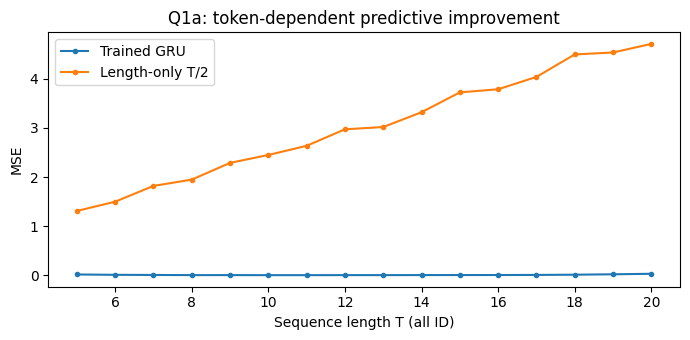

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ID_LENGTHS, [id_report[T]['model']['mse'] for T in ID_LENGTHS],
        marker='o', markersize=3, label='Trained GRU')
ax.plot(ID_LENGTHS, [id_report[T]['length_only_pT']['mse'] for T in ID_LENGTHS],
        marker='o', markersize=3, label='Length-only T/2')
ax.set(xlabel='Sequence length T (all ID)', ylabel='MSE',
       title='Q1a: token-dependent predictive improvement')
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

## Signed errors conditional on true count at fixed ID length
The GRU may outperform $T/2$ on average yet show systematic errors for particular realised counts. At fixed $T$, we inspect the signed bias $\mathbb E[\hat Y-Y\mid T,Y=k]$ and rounded-count accuracy. We must record the number $n$ of examples supporting each count: extreme counts may be rare, so individual rows may be noisy or absent. Conditioning on the count does not identify whether the GRU encodes elapsed time.

In [14]:
for T in (10, 20):
    print()
    print(f'ID length T={T}: conditional errors on observed true counts')
    print('k      n     bias      MAE   rounded_acc')
    for k, metrics in id_report[T]['model_by_true_count'].items():
        caution = '  [few samples]' if metrics['n'] < 20 else ''
        print(f"{k:2d} {metrics['n']:6d} {metrics['bias']:+8.3f} "
              f"{metrics['mae']:8.3f} {metrics['rounded_accuracy']:11.3f}{caution}")



ID length T=10: conditional errors on observed true counts
k      n     bias      MAE   rounded_acc
 0      1   +0.459    0.459       1.000  [few samples]
 1      9   +0.249    0.249       1.000  [few samples]
 2     41   +0.097    0.097       1.000
 3    119   +0.002    0.019       1.000
 4    241   -0.043    0.043       1.000
 5    237   -0.052    0.052       1.000
 6    204   -0.030    0.030       1.000
 7    120   +0.015    0.022       1.000
 8     40   +0.065    0.065       1.000
 9     10   +0.102    0.102       1.000  [few samples]
10      2   +0.123    0.123       1.000  [few samples]

ID length T=20: conditional errors on observed true counts
k      n     bias      MAE   rounded_acc
 4      4   -0.081    0.091       1.000  [few samples]
 5     20   -0.124    0.124       1.000
 6     32   -0.087    0.088       1.000
 7     81   -0.032    0.036       1.000
 8    120   +0.022    0.026       1.000
 9    177   +0.082    0.082       1.000
10    181   +0.105    0.105       1.000
11 

### Observations
Does low average ID prediction error conceal systematic weaknesses at particular realised counts?

**Method.** The idea here is to condition the held-out ID evaluation results on both sequence length and true count, examining cases for $T=10$ and $T=20$.

For each observed count $k$, the notebook reports the number of evaluation examples, mean signed prediction bias, MAE, and rounded-count accuracy.

At $T=10$, all 1,024 evaluated examples round to their correct counts. Small continuous biases remain, particularly at rare count values.

At $T=20$, all 31 rounded-count errors can be seen to occur among the observed sequences containing 14–16 ones.

The average signed biases in these groups are:

$$
\begin{aligned}
k=14 &: -0.490,\\
k=15 &: -0.798,\\
k=16 &: -1.270.
\end{aligned}
$$

By contrast, the model achieves 100% rounded accuracy on all observed count groups from $k=4$ through $k=13$.

**Interpretation.**

The slight decline in ID accuracy near the maximum training length is not uniformly distributed across the count range. It is perhaps notable that errors concentrate in the upper tail of the conditional binomial distribution, 
which is compatible with an imperfect learned numerical representation or reduced accuracy on relatively rare target compositions.

Having said that, the most extreme count groups have small sample sizes. In particular, only 12 examples with count 15 and three with count 16 were observed.

The evidence is sufficient to identify a potential weakness, but insufficient to characterise its generality or internal mechanism.

## Exactly matched count across different lengths
Now fix $K=6$ and vary $T\in{10,15,20,30,40,80}$, drawing uniformly random positions for the six ones at each length. This gives independent random arrangements conditional on $(T,K)$, not repeated copies of one deterministic sequence.

The model's average prediction is $6+\operatorname{Bias}(T,K=6)$. Changing $T$ here also changes the proportion $6/T$ of ones, the number and spacing of zeros, and how unusual the condition is under Bernoulli(0.5) sampling. Consequently, prediction changes establish dependence on the combined condition, not the causal effect of length alone. Conditions with $T>20$ are OOD in length; any claim about successful length extrapolation remains conditional on Q0.

The reference $T/2$ remains displayed only as the original unconditional Bernoulli predictor, and must not be treated as the optimal predictor when the count is fixed to six.

In [15]:
Q1_COUNT = 6
Q1_LENGTHS = (10, 15, 20, 30, 40, 80)
Q1_EXACT_BATCH = 512
rng = torch.Generator().manual_seed(EXACT_COUNT_SEED)
matched_count_batches = {
    T: exp.exact_count_batch(T, Q1_COUNT, batch_size=Q1_EXACT_BATCH,
                             order='random', device=DEVICE, generator=rng)
    for T in Q1_LENGTHS
}
matched_count_report = exp.evaluate_predictive(model, matched_count_batches, p=P)

print('T    region    n   k/T    mean_pred      bias      MAE  rounded_acc')
for T in Q1_LENGTHS:
    row = matched_count_report[T]
    m = row['model']
    mean_pred = Q1_COUNT + m['bias']
    print(f"{T:2d} {row['length_region']:>10} {m['n']:4d} {Q1_COUNT / T:5.3f} "
          f"{mean_pred:11.3f} {m['bias']:+9.3f} {m['mae']:8.3f} "
          f"{m['rounded_accuracy']:11.3f}")


T    region    n   k/T    mean_pred      bias      MAE  rounded_acc
10  ID_length  512 0.600       5.972    -0.028    0.028       1.000
15  ID_length  512 0.400       5.935    -0.065    0.065       1.000
20  ID_length  512 0.300       5.909    -0.091    0.092       1.000
30 OOD_length  512 0.200       5.859    -0.141    0.142       1.000
40 OOD_length  512 0.150       5.823    -0.177    0.189       1.000
80 OOD_length  512 0.075       5.635    -0.365    0.384       0.691


### Observations

How does the trained GRU respond when sequence length increases while the true count remains fixed?

**Method.** For each

$$
T\in\{10,15,20,30,40,80\},
$$

generate 512 sequences containing exactly six ones, with their positions sampled uniformly among the possible arrangements.

The target is always $K=6$. We measure mean prediction, signed bias, MAE and rounded-count accuracy.

**Results.** The mean prediction decreases from 5.972 at $T=10$ to 5.635 at $T=80$. Rounded count accuracy remains 100% through $T=40$, but declines to 69.1% at $T=80$.
The most notable observation is the gradual deterioration in fixed count prediction under increasingly long and sparse input sequences. We don't isolate the mechanism here, as that is for Q2.

Worth noting that the model retains substantial predictive accuracy at some lengths beyond the training interval, without displaying perfect invariance to the tested sequence conditions.

**Interpretation.**

The fixed target demonstrates that increasing numerical count magnitude is not necessary for errors to emerge. However, the experiment does not isolate elapsed time. As $T$ increases, the proportion of ones decreases, the typical spacing between counted tokens changes, and the selected count becomes increasingly atypical of Bernoulli(0.5) sampling. Consequently, the observed downward prediction drift establishes sensitivity to the joint exact count/length condition.

The results demonstrate that a trained GRU can retain useful finite range counting behaviour beyond the training length boundary, despite its theoretical inability to implement unbounded scalar count regression.

## Plot of matched-count predictions
The figure plots mean signed prediction error against sequence length for sequences containing exactly six ones. The horizontal zero line represents an unbiased prediction, while the vertical reference at $T=20$ marks the maximum training length.

Because the target remains fixed, departures from zero reveal systematic prediction changes under the jointly varying length and token-composition conditions. The figure does not isolate the causal contribution of elapsed time.

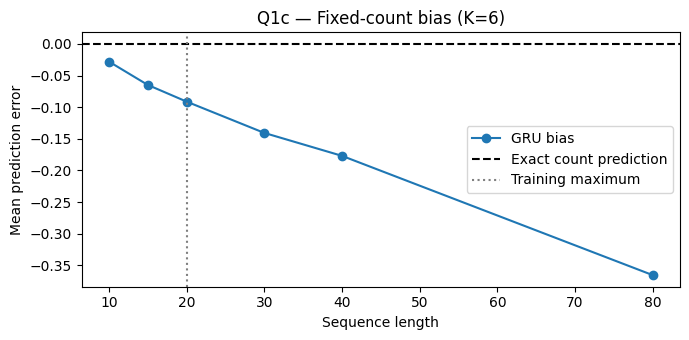

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.5))

bias = [
    matched_count_report[T]["model"]["bias"]
    for T in Q1_LENGTHS
]

ax.plot(Q1_LENGTHS, bias, marker="o", label="GRU bias")
ax.axhline(0, color="black", linestyle="--",
           label="Exact count prediction")
ax.axvline(20, color="grey", linestyle=":",
           label="Training maximum")

ax.set(
    xlabel="Sequence length",
    ylabel="Mean prediction error",
    title="Q1c — Fixed-count bias (K=6)",
)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)
